<a href="https://colab.research.google.com/github/AfrinAkter020/Flutter-Task-Manager-App/blob/main/Boro_Crop_Yield_ML_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

boro_file = "/content/boro_fertilizer_proxy_2015_2025_merged (1).csv"
weather_file = "/content/merged_bangladesh_meteorological_data_2015_2025-v3 (1) (1).csv"

boro_df = pd.read_csv(boro_file)
met_df = pd.read_csv(weather_file)

# 2. Cleaning Boro Data
boro_clean = boro_df[boro_df['Sl_No'].astype(str).str.isnumeric() == True].copy()
num_cols = ['Boro_Area_Hectares', 'Boro_Production_MT', 'Boro_Yield_Rate_MT_HA',
            'Proxy_Urea_MT', 'Proxy_TSP_MT', 'Proxy_DAP_MT', 'Proxy_MOP_MT']

for col in num_cols:
    boro_clean[col] = pd.to_numeric(boro_clean[col], errors='coerce')

# 3. Feature Engineering: Calculating fertilizer application per hectare (Normalize inputs)
boro_clean['Urea_Per_HA'] = boro_clean['Proxy_Urea_MT'] / boro_clean['Boro_Area_Hectares']
boro_clean['DAP_Per_HA'] = boro_clean['Proxy_DAP_MT'] / boro_clean['Boro_Area_Hectares']
boro_clean['TSP_Per_HA'] = boro_clean['Proxy_TSP_MT'] / boro_clean['Boro_Area_Hectares']
boro_clean['MOP_Per_HA'] = boro_clean['Proxy_MOP_MT'] / boro_clean['Boro_Area_Hectares']


# 4. Aggregation and merging of weather data
met_yearly = met_df.groupby(['DISTRICT', 'YEAR'])[['PRECTOTCORR', 'T2M_MAX', 'T2M_MIN', 'RH2M']].mean().reset_index()
met_yearly['Year'] = met_yearly['YEAR'].astype(str) + "-" + (met_yearly['YEAR'] + 1).astype(str)

boro_clean['District_clean'] = boro_clean['District'].astype(str).str.strip()
met_yearly['District_clean'] = met_yearly['DISTRICT'].astype(str).str.strip()

ml_df = pd.merge(boro_clean, met_yearly, on=['District_clean', 'Year'], how='inner').dropna()

print("Data preparation complete! Total district-year data points:", len(ml_df))
display(ml_df[['District', 'Year', 'Boro_Area_Hectares', 'Boro_Production_MT', 'Urea_Per_HA', 'DAP_Per_HA', 'PRECTOTCORR', 'T2M_MAX']].head(3))

Data preparation complete! Total district-year data points: 290


,District,Year,Boro_Area_Hectares,Boro_Production_MT,Urea_Per_HA,DAP_Per_HA,PRECTOTCORR,T2M_MAX
0,Brahmanbaria,2015-2016,105265.0,410659.0,0.480034,0.137871,3.371429,32.435714
1,Cumilla,2015-2016,158893.0,581778.0,0.480034,0.137871,2.482857,32.110000
2,Feni,2015-2016,31797.0,113281.0,0.480034,0.137871,1.878571,31.672857


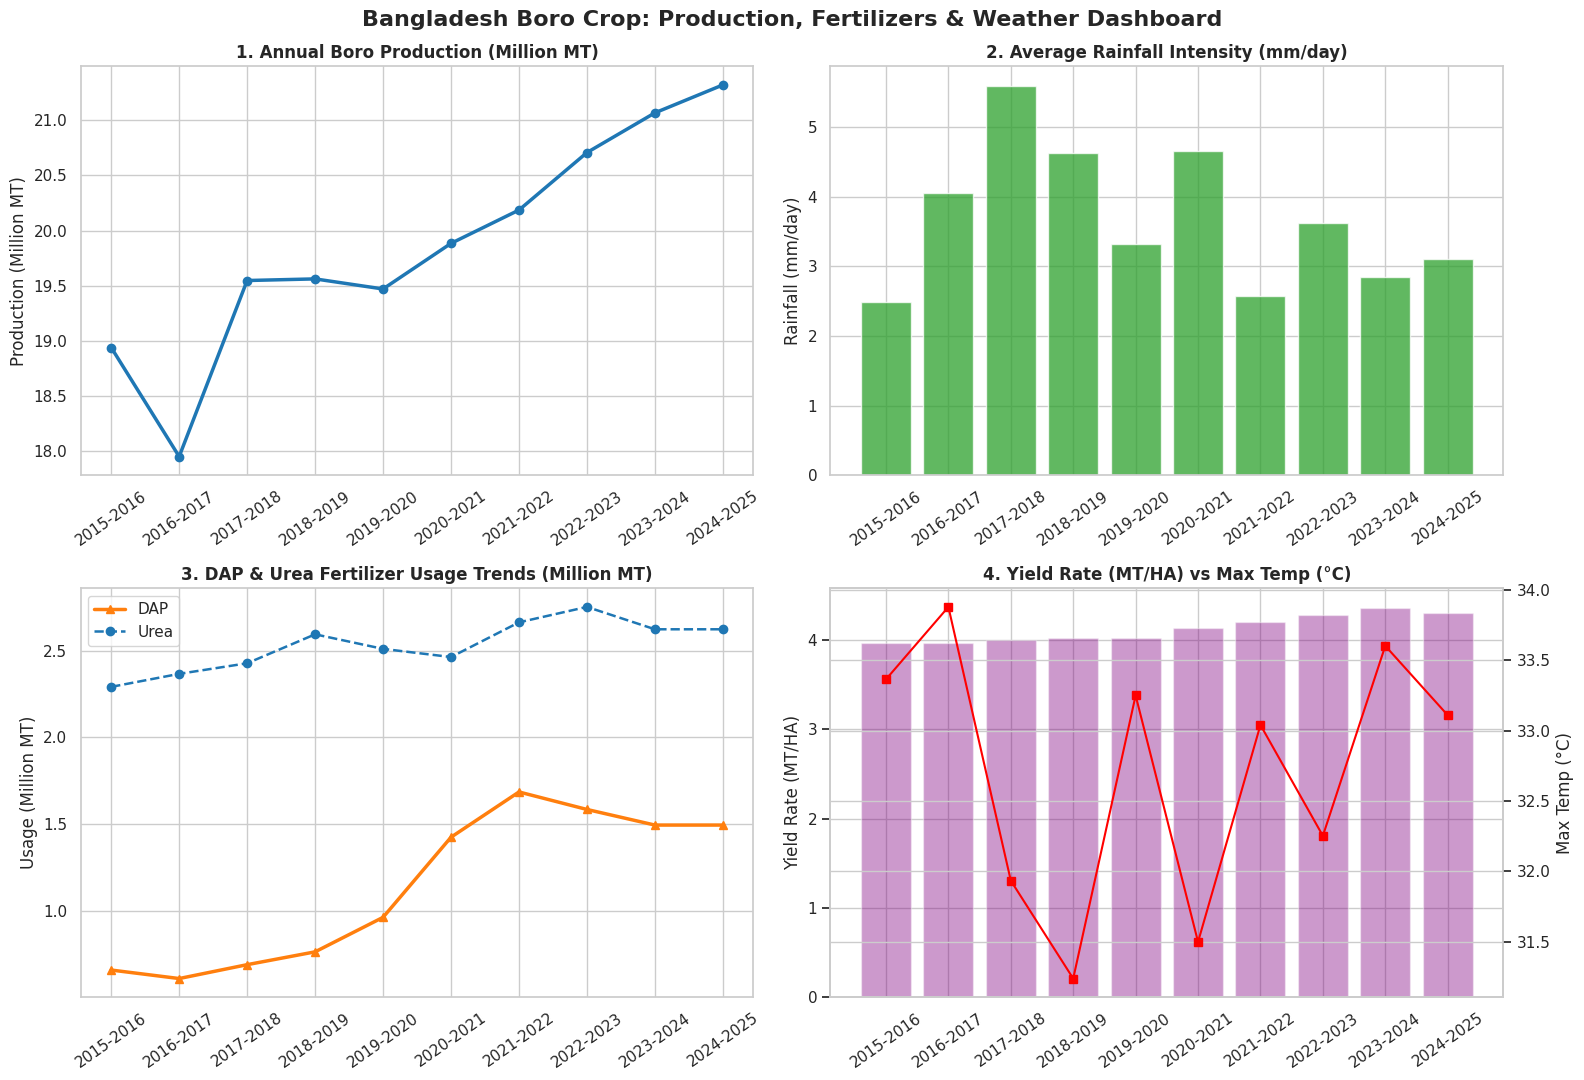

In [50]:
# Part 2: Dashboard (2x2 Grid with 4 Main National Trends)
sns.set_theme(style="whitegrid", palette="colorblind")
fig, axs = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle("Bangladesh Boro Crop: Production, Fertilizers & Weather Dashboard", fontsize=16, fontweight='bold')

# ১.Total annual production (Million MT)
prod_trend = boro_clean.groupby('Year')['Boro_Production_MT'].sum() / 1e6
axs[0, 0].plot(prod_trend.index, prod_trend.values, marker='o', color='#1f77b4', linewidth=2.5)
axs[0, 0].set_title("1. Annual Boro Production (Million MT)", fontweight='bold')
axs[0, 0].tick_params(axis='x', rotation=35)
axs[0, 0].set_ylabel("Production (Million MT)")

# ২. Intensity of rainfall (mm/day)
rain_trend = ml_df.groupby('Year')['PRECTOTCORR'].mean()
axs[0, 1].bar(rain_trend.index, rain_trend.values, color='#2ca02c', alpha=0.75)
axs[0, 1].set_title("2. Average Rainfall Intensity (mm/day)", fontweight='bold')
axs[0, 1].tick_params(axis='x', rotation=35)
axs[0, 1].set_ylabel("Rainfall (mm/day)")

# ৩. Use of DAP and Urea Fertilizers (Million MT)
fert_trend = boro_clean.groupby('Year')[['Proxy_Urea_MT', 'Proxy_DAP_MT', 'Proxy_TSP_MT', 'Proxy_MOP_MT']].sum() / 1e6
axs[1, 0].plot(fert_trend.index, fert_trend['Proxy_DAP_MT'], label='DAP', marker='^', color='#ff7f0e', linewidth=2.5)
axs[1, 0].plot(fert_trend.index, fert_trend['Proxy_Urea_MT'], label='Urea', marker='o', color='#1f77b4', linewidth=1.8, linestyle='--')
axs[1, 0].set_title("3. DAP & Urea Fertilizer Usage Trends (Million MT)", fontweight='bold')
axs[1, 0].tick_params(axis='x', rotation=35)
axs[1, 0].set_ylabel("Usage (Million MT)")
axs[1, 0].legend()

# ৪. Average Yield vs. Maximum Temperature
weather_yield = ml_df.groupby('Year')[['Boro_Yield_Rate_MT_HA', 'T2M_MAX']].mean()
ax4_twin = axs[1, 1].twinx()
axs[1, 1].bar(weather_yield.index, weather_yield['Boro_Yield_Rate_MT_HA'], alpha=0.4, color='purple', label='Yield (MT/HA)')
ax4_twin.plot(weather_yield.index, weather_yield['T2M_MAX'], color='red', marker='s', label='Max Temp (°C)')
axs[1, 1].set_title("4. Yield Rate (MT/HA) vs Max Temp (°C)", fontweight='bold')
axs[1, 1].tick_params(axis='x', rotation=35)
axs[1, 1].set_ylabel("Yield Rate (MT/HA)")
ax4_twin.set_ylabel("Max Temp (°C)")

plt.tight_layout()
plt.show()

In [44]:
# Part 3: ML Model Training (Two-Step Weather + Fertilizer + Area Model)
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

# ১.Input features(Weather + All 4 Fertilizers per HA)
features = ['Urea_Per_HA', 'DAP_Per_HA', 'TSP_Per_HA', 'MOP_Per_HA',
            'PRECTOTCORR', 'T2M_MAX', 'T2M_MIN', 'RH2M']

X = ml_df[features]
y_yield = ml_df['Boro_Yield_Rate_MT_HA']  # Step 1 Target: Yield Rate


# 2. Train-Test Split (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y_yield, test_size=0.2, random_state=42)

# 3. Training the Random Forest Regressor Model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# 4. Yield Rate Prediction
y_pred_yield = rf_model.predict(X_test)


# 5. Calculating the final total production by adjusting for cultivated land (Step 2)
test_area = ml_df.loc[X_test.index, 'Boro_Area_Hectares']
actual_production = ml_df.loc[X_test.index, 'Boro_Production_MT']

# Predicted Production = Predicted Yield Rate * Cultivated Area
predicted_production = y_pred_yield * test_area

final_r2 = r2_score(actual_production, predicted_production) * 100
final_mae = mean_absolute_error(actual_production, predicted_production)

print("===  Machine Learning Model Performance ===")
print(f"1. R² Score for Yield Rate Prediction: {r2_score(y_test, y_pred_yield) * 100:.2f}%")
print(f"2. Accuracy of the final total paddy production prediction:{final_r2:.2f}%")
print(f"3. Mean Absolute Error: {final_mae:,.0f} Metric Tons")

===  Machine Learning Model Performance ===
1. R² Score for Yield Rate Prediction: 3.15%
2. Accuracy of the final total paddy production prediction:97.96%
3. Mean Absolute Error: 27,877 Metric Tons


/tmp/ipykernel_2646/2411898815.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, ax=ax1, palette="mako")


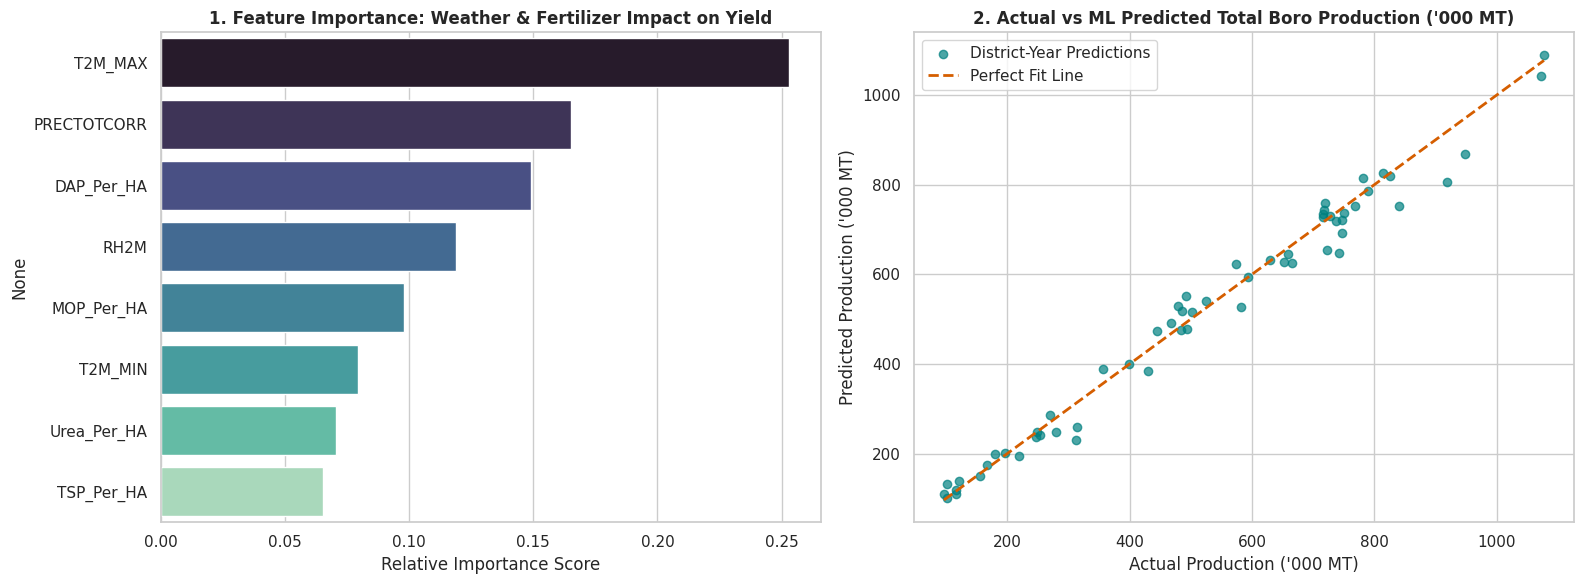

In [45]:
# Part 4: Visualization of ML Feature Importance & Predictions

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))


# 1. Analysis of Feature Importance (Weather & Fertilizer Impact on Yield)
importances = pd.Series(rf_model.feature_importances_, index=features).sort_values(ascending=False)
sns.barplot(x=importances.values, y=importances.index, ax=ax1, palette="mako")
ax1.set_title("1. Feature Importance: Weather & Fertilizer Impact on Yield", fontweight='bold')
ax1.set_xlabel("Relative Importance Score")

# 2. Actual Production vs. ML Model-Predicted Production
ax2.scatter(actual_production / 1e3, predicted_production / 1e3, color='teal', alpha=0.7, label='District-Year Predictions')
ax2.plot([actual_production.min() / 1e3, actual_production.max() / 1e3],
         [actual_production.min() / 1e3, actual_production.max() / 1e3], 'r--', lw=2, label='Perfect Fit Line')
ax2.set_title("2. Actual vs ML Predicted Total Boro Production ('000 MT)", fontweight='bold')
ax2.set_xlabel("Actual Production ('000 MT)")
ax2.set_ylabel("Predicted Production ('000 MT)")
ax2.legend()

plt.tight_layout()
plt.show()